Dataset Shape: 1597 rows, 27 columns
Columns: ['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded', 'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer', 'manufacturerNumber', 'name', 'prices', 'reviews.date', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes', 'upc', 'weight']

Saved scored dataset to 'amazon_reviews_with_sentiment.csv'

--- OVERALL SENTIMENT BREAKDOWN ---
           Count  Percentage (%)
sentiment                       
Positive    1411           88.35
Negative     137            8.58
Neutral       49            3.07

--- EMOTION & TONE BREAKDOWN ---
emotion_tone
Joy / High Satisfaction       1251
Mild Approval / Trust          160
Anger / Strong Frustration      70
Disappointment / Concern        67
Objective / Neutral             27
Mixed / Ambivalent              22
Name: count, dtype: int64

--- SENTIMENT SCORE BY

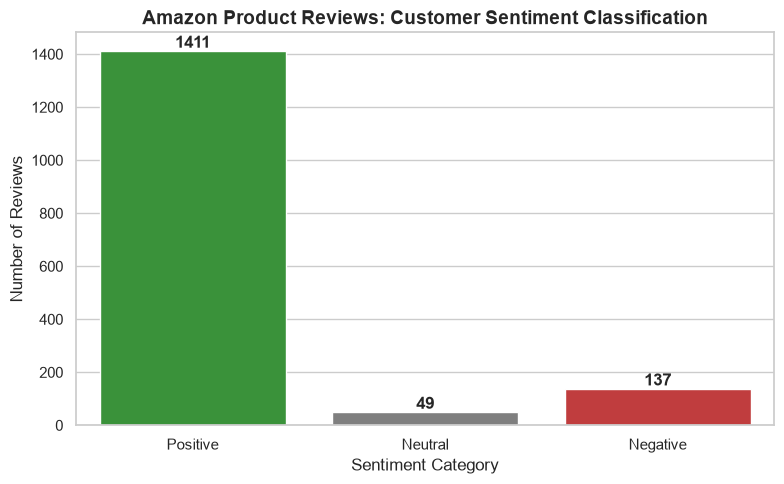

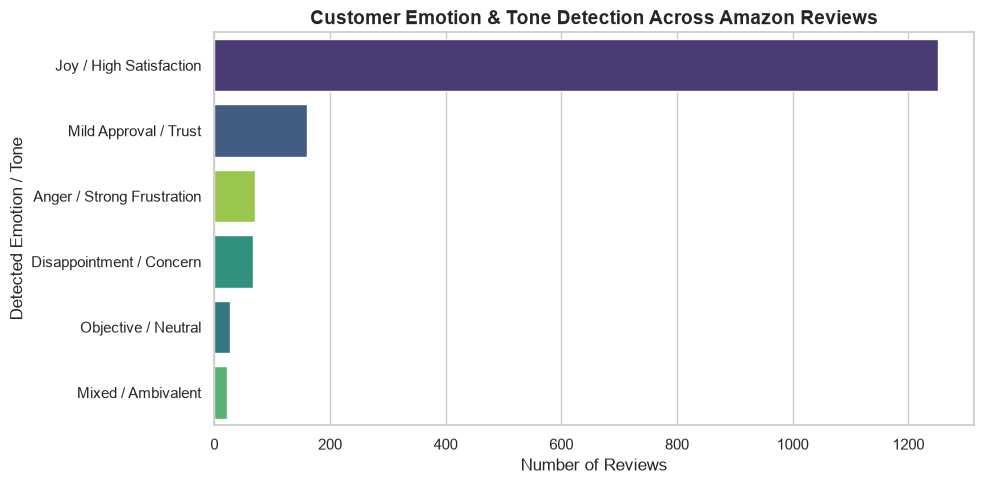

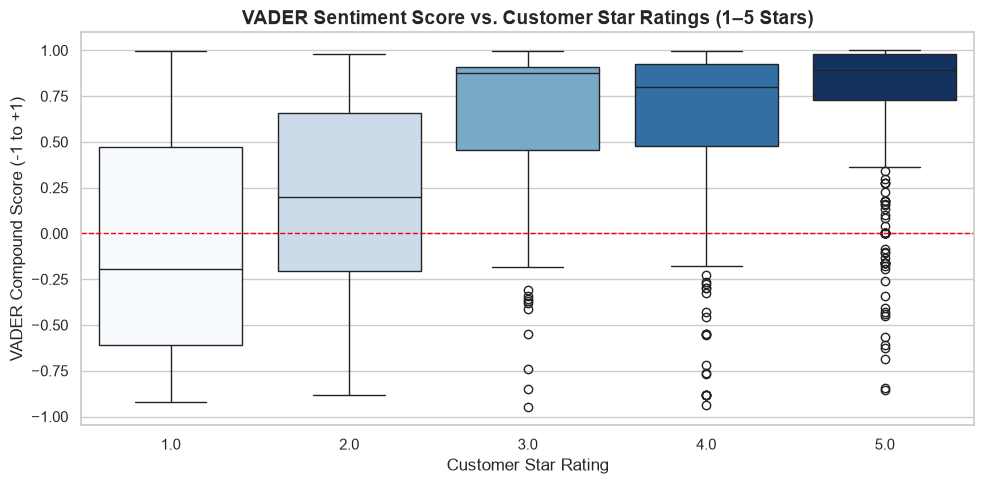


--- TOP PRAISE KEYWORDS (INFORMING MARKETING) ---
[('like', 1192), ('your', 927), ('these', 796), ('headphones', 779), ('great', 770), ('sound', 763), ('prime', 725), ('them', 720), ('dont', 716), ('than', 707)]

--- TOP COMPLAINT KEYWORDS (INFORMING PRODUCT DEVELOPMENT) ---
[('ipad', 103), ('version', 97), ('years', 87), ('review', 82), ('last', 81), ('will', 73), ('than', 66), ('your', 65), ('also', 64), ('year', 52)]


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from textblob import TextBlob
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download VADER lexicon (runs once in 2 seconds)
nltk.download("vader_lexicon", quiet=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. LOAD & INSPECT AMAZON PRODUCT REVIEWS DATASET
df = pd.read_csv("7817_1.csv")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("Columns:", list(df.columns))

# 2. DATA CLEANING & TEXT PREPROCESSING
cols = [c for c in ["brand", "categories", "name", "reviews.rating", "reviews.title", "reviews.text", "reviews.doRecommend"] if c in df.columns]
df_clean = df[cols].dropna(subset=["reviews.text"]).copy()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text) # Remove URLs
    text = re.sub(r"[^a-z\s]", "", text) # Keep letters and spaces only
    text = re.sub(r"\s+", " ", text).strip() # Remove extra spaces
    return text

df_clean["cleaned_review"] = df_clean["reviews.text"].apply(clean_text)

# 3. DUAL NLP LEXICON SCORING (VADER + TEXTBLOB) & EMOTION DETECTION
sia = SentimentIntensityAnalyzer()

df_clean["vader_compound"] = df_clean["reviews.text"].apply(lambda x: sia.polarity_scores(str(x))["compound"])
df_clean["textblob_polarity"] = df_clean["cleaned_review"].apply(lambda x: TextBlob(x).sentiment.polarity)
df_clean["subjectivity"] = df_clean["cleaned_review"].apply(lambda x: TextBlob(x).sentiment.subjectivity)

def classify_sentiment(compound):
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"

def detect_emotion_tone(row):
    c = row["vader_compound"]
    subj = row["subjectivity"]
    if c >= 0.6:
        return "Joy / High Satisfaction"
    elif c >= 0.05:
        return "Mild Approval / Trust"
    elif c <= -0.5:
        return "Anger / Strong Frustration"
    elif c <= -0.05:
        return "Disappointment / Concern"
    else:
        return "Objective / Neutral" if subj < 0.4 else "Mixed / Ambivalent"

df_clean["sentiment"] = df_clean["vader_compound"].apply(classify_sentiment)
df_clean["emotion_tone"] = df_clean.apply(detect_emotion_tone, axis=1)

# Save scored dataset
df_clean.to_csv("amazon_reviews_with_sentiment.csv", index=False)
print("\nSaved scored dataset to 'amazon_reviews_with_sentiment.csv'")

# 4. SENTIMENT PATTERNS & SUMMARY INSIGHTS
print("\n--- OVERALL SENTIMENT BREAKDOWN ---")
sent_summary = pd.DataFrame({
    "Count": df_clean["sentiment"].value_counts(),
    "Percentage (%)": (df_clean["sentiment"].value_counts(normalize=True) * 100).round(2)
})
print(sent_summary)

print("\n--- EMOTION & TONE BREAKDOWN ---")
print(df_clean["emotion_tone"].value_counts())

if "reviews.rating" in df_clean.columns:
    print("\n--- SENTIMENT SCORE BY STAR RATING (1-5 STARS) ---")
    print(df_clean.groupby("reviews.rating")[["vader_compound", "textblob_polarity"]].agg(["count", "mean"]).round(3))

# 5. VISUALIZATIONS (SAVED AS HIGH-RES PNG FOR GITHUB)
# Chart 1: Overall Sentiment Classification (Positive, Neutral, Negative)
plt.figure(figsize=(8, 5))
palette = {"Positive": "#2ca02c", "Neutral": "#7f7f7f", "Negative": "#d62728"}
ax = sns.countplot(data=df_clean, x="sentiment", order=["Positive", "Neutral", "Negative"], hue="sentiment", palette=palette, legend=False)
plt.title("Amazon Product Reviews: Customer Sentiment Classification", fontsize=14, fontweight="bold")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.savefig("sentiment_chart1_distribution.png", dpi=300)
plt.show()

# Chart 2: Emotion & Tone Breakdown
plt.figure(figsize=(10, 5))
emotion_order = df_clean["emotion_tone"].value_counts().index
sns.countplot(data=df_clean, y="emotion_tone", order=emotion_order, hue="emotion_tone", palette="viridis", legend=False)
plt.title("Customer Emotion & Tone Detection Across Amazon Reviews", fontsize=14, fontweight="bold")
plt.xlabel("Number of Reviews")
plt.ylabel("Detected Emotion / Tone")
plt.tight_layout()
plt.savefig("sentiment_chart2_emotions.png", dpi=300)
plt.show()

# Chart 3: VADER Sentiment Score vs. Customer Star Ratings
if "reviews.rating" in df_clean.columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_clean.dropna(subset=["reviews.rating"]), x="reviews.rating", y="vader_compound", hue="reviews.rating", palette="Blues", legend=False)
    plt.axhline(0, color="red", linestyle="--", linewidth=1)
    plt.title("VADER Sentiment Score vs. Customer Star Ratings (1–5 Stars)", fontsize=14, fontweight="bold")
    plt.xlabel("Customer Star Rating")
    plt.ylabel("VADER Compound Score (-1 to +1)")
    plt.tight_layout()
    plt.savefig("sentiment_chart3_rating_vs_sentiment.png", dpi=300)
    plt.show()

# 6. ACTIONABLE MARKETING & PRODUCT DEVELOPMENT INSIGHTS (TOP KEYWORDS)
stopwords = {"the", "and", "to", "a", "i", "it", "is", "of", "for", "this", "in", "my", "with", "on", "that", "was", "have", "are", "but", "not", "you", "as", "very", "so", "be", "they", "we", "had", "has", "at", "or", "if", "an", "from", "all", "just", "me", "out", "up", "when", "what", "there", "can", "more", "would", "get", "one", "use", "amazon", "kindle", "fire", "tablet", "device", "product"}

pos_words = [w for text in df_clean[df_clean["sentiment"] == "Positive"]["cleaned_review"] for w in text.split() if w not in stopwords and len(w) > 3]
neg_words = [w for text in df_clean[df_clean["sentiment"] == "Negative"]["cleaned_review"] for w in text.split() if w not in stopwords and len(w) > 3]

print("\n--- TOP PRAISE KEYWORDS (INFORMING MARKETING) ---")
print(Counter(pos_words).most_common(10))

print("\n--- TOP COMPLAINT KEYWORDS (INFORMING PRODUCT DEVELOPMENT) ---")
print(Counter(neg_words).most_common(10))